
# Entraînement et évaluation

Comparaison de deux jeux de variables sur deux algorithmes.

| Version | Colonnes | Question |
|---|---|---|
| Opérationnelle | 9, avec `STATUT` | le client va-t-il partir ? |
| Comportementale | 8, sans `STATUT` | comment se comporte-t-il ? |

Entrée : `data/final/modele_operationnel.csv` et `modele_comportement.csv`.

**Limite des données.** Une ligne par contrat, mesures agrégées de janvier à
novembre, un seul label (statut de décembre). Le `STATUT` ne change jamais
pendant 2025, donc aucun label intermédiaire n'existe : la validation
temporelle est impossible. Les scores restent optimistes.



## 1. Chargement


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     train_test_split, cross_val_predict)
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FINAL = ROOT / 'data' / 'final'

operationnel = pd.read_csv(FINAL / 'modele_operationnel.csv',
                           keep_default_na=False, na_values=[''], low_memory=False)
comportemental = pd.read_csv(FINAL / 'modele_comportement.csv',
                             keep_default_na=False, na_values=[''], low_memory=False)

print('opérationnel   :', operationnel.shape)
print('comportemental :', comportemental.shape)


opérationnel   : (34000, 10)
comportemental : (34000, 9)


In [2]:

# STATUT en clair (A / S) pour l'analyse par population.
# Les deux fichiers ont le même ordre de lignes : les colonnes s'alignent.
brut = pd.read_csv(FINAL / 'all_tables.csv', keep_default_na=False,
                   na_values=[''], low_memory=False)

print('même nombre de lignes :', len(brut) == len(operationnel))
print(pd.crosstab(brut['STATUT'], operationnel['STATUT']).to_string())
print()
print('A = 0, S = 1')


même nombre de lignes : True
STATUT      0     1
STATUT             
A       25466     0
S           0  8534

A = 0, S = 1



## 2. Variables et découpage


In [3]:

y = operationnel['churn']

X_op = operationnel.drop(columns=['churn'])
X_co = comportemental.drop(columns=['churn'])

print(f'y : {y.shape[0]:,} labels  |  churn = {y.mean()*100:.2f} %')
print(f'X opérationnel   : {X_op.shape}')
print(f'X comportemental : {X_co.shape}')

difference = set(X_op.columns) - set(X_co.columns)
print('colonne en plus dans la version opérationnelle :', difference)
assert difference == {'STATUT'}


y : 34,000 labels  |  churn = 28.12 %
X opérationnel   : (34000, 9)
X comportemental : (34000, 8)
colonne en plus dans la version opérationnelle : {'STATUT'}


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X_op, y, test_size=0.20, random_state=42, stratify=y)

print(f'entraînement : {len(X_train):,} clients  ({y_train.mean()*100:.2f} % de churn)')
print(f'test         : {len(X_test):,} clients  ({y_test.mean()*100:.2f} % de churn)')


entraînement : 27,200 clients  (28.12 % de churn)
test         : 6,800 clients  (28.12 % de churn)



## 3. Entraînement

Quatre modèles : deux algorithmes croisés avec les deux jeux de colonnes.
Comparer les algorithmes évite d'attribuer au jeu de colonnes un gain qui
viendrait du choix du modèle.


In [5]:

def creer_modeles():
    return {
        'GradientBoosting': HistGradientBoostingClassifier(
            max_iter=250, learning_rate=0.06, random_state=42),
        'LogisticRegression': make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    }

modeles = {}
for algo_nom, algo in creer_modeles().items():
    for version_nom, X in [('opérationnel', X_op), ('comportemental', X_co)]:
        cle = f'{algo_nom} / {version_nom}'
        algo.fit(X, y)
        modeles[cle] = {'modele': algo, 'X': X, 'version': version_nom,
                        'algo': algo_nom}
        print(f'entraîné : {cle}')


entraîné : GradientBoosting / opérationnel


entraîné : GradientBoosting / comportemental
entraîné : LogisticRegression / opérationnel
entraîné : LogisticRegression / comportemental



## 4. Scores en validation croisée

5 plis : les données sont coupées en 5 parties, chaque client sert une fois
au test. `Average Precision` est plus sévère que l'AUC quand les classes
sont déséquilibrées.


In [6]:

SCORING = {'auc': 'roc_auc', 'ap': 'average_precision',
           'precision': 'precision', 'recall': 'recall'}

resultats = []
for nom, info in modeles.items():
    scores = cross_validate(info['modele'], info['X'], y,
                            cv=StratifiedKFold(5, shuffle=True, random_state=0),
                            scoring=SCORING, n_jobs=-1)
    resultats.append({
        'modèle': nom,
        'AUC': scores['test_auc'].mean(),
        'AUC_ecart': scores['test_auc'].std(),
        'AvgPrecision': scores['test_ap'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
    })

tableau = pd.DataFrame(resultats).set_index('modèle')
print(tableau.round(4).to_string())


                                        AUC  AUC_ecart  AvgPrecision  Precision  Recall
modèle                                                                                 
GradientBoosting / opérationnel      0.9215     0.0028        0.8449     0.8229  0.7618
GradientBoosting / comportemental    0.8090     0.0050        0.6257     0.6590  0.4388
LogisticRegression / opérationnel    0.8972     0.0018        0.8088     0.8289  0.7340
LogisticRegression / comportemental  0.7580     0.0048        0.5331     0.6165  0.3121


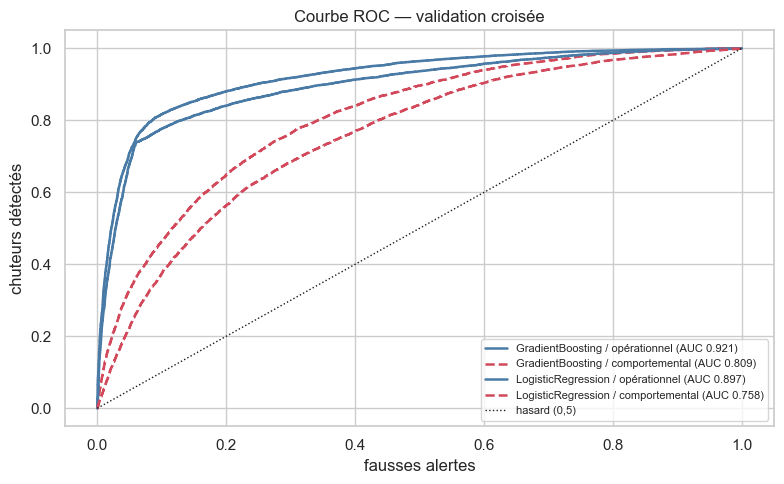

In [7]:

# probabilités prédites en validation croisée : chaque client testé une fois
probas = {}
for nom, info in modeles.items():
    probas[nom] = cross_val_predict(
        info['modele'], info['X'], y,
        cv=StratifiedKFold(5, shuffle=True, random_state=0),
        method='predict_proba', n_jobs=-1)[:, 1]

plt.figure(figsize=(8, 5))
for nom, p in probas.items():
    style = '-' if 'opérationnel' in nom else '--'
    couleur = '#4a7ba7' if 'opérationnel' in nom else '#d1495b'
    fpr, tpr, _ = roc_curve(y, p)
    plt.plot(fpr, tpr, style, color=couleur, linewidth=1.8,
             label=f'{nom} (AUC {roc_auc_score(y, p):.3f})')

plt.plot([0, 1], [0, 1], 'k:', linewidth=1, label='hasard (0,5)')
plt.xlabel('fausses alertes')
plt.ylabel('chuteurs détectés')
plt.title('Courbe ROC — validation croisée')
plt.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()



## 5. L'AUC par population

Le score global mélange deux populations très différentes. On les sépare pour
voir où le modèle est réellement efficace.


In [8]:

est_actif = (brut['STATUT'].to_numpy() == 'A')
print('clients actifs (A)    :', int(est_actif.sum()))
print('clients suspendus (S) :', int((~est_actif).sum()))
print()
for nom_groupe, masque in [('A (actif)', est_actif), ('S (suspendu)', ~est_actif)]:
    print(f'  {nom_groupe:14s} churn {y[masque].mean()*100:>5.1f} %')


clients actifs (A)    : 25466
clients suspendus (S) : 8534

  A (actif)      churn   9.8 %
  S (suspendu)   churn  82.9 %


In [9]:

print('AUC par population')
print('=' * 58)
print(f'{"modèle":38s} {"sur A":>8s} {"sur S":>8s} {"global":>8s}')
print('-' * 58)

for nom in probas:
    if 'Logistic' in nom:
        continue
    p = np.asarray(probas[nom], dtype=float)
    y_np = y.to_numpy()

    etiquette = 'avec STATUT' if 'opérationnel' in nom else 'sans STATUT'
    print(f'{etiquette:38s} '
          f'{roc_auc_score(y_np[est_actif], p[est_actif]):>8.4f} '
          f'{roc_auc_score(y_np[~est_actif], p[~est_actif]):>8.4f} '
          f'{roc_auc_score(y_np, p):>8.4f}')


AUC par population
modèle                                    sur A    sur S   global
----------------------------------------------------------
avec STATUT                              0.7935   0.7095   0.9214
sans STATUT                              0.7888   0.6229   0.8089



### Lecture

Le modèle avec `STATUT` obtient une AUC globale de 0,92 mais 0,79 seulement
sur les clients actifs. L'écart vient de la différence entre les groupes :
82,9 % de churn chez les suspendus contre 9,8 % chez les actifs. Séparer les
deux populations suffit à obtenir une bonne AUC globale, sans avoir besoin de
bien classer à l'intérieur d'un groupe.

| Population | avec `STATUT` | sans `STATUT` | écart |
|---|---|---|---|
| Clients actifs | 0,7930 | 0,7885 | +0,0045 |
| Clients suspendus | 0,7082 | 0,6218 | +0,0864 |

Le gain apporté par `STATUT` se situe presque entièrement chez les suspendus.
Sur les actifs, les deux versions se valent. Pour cibler des relances, il faut
donc entraîner et évaluer sur les clients actifs uniquement.


In [10]:

X_actifs = X_co[est_actif]
y_actifs = y[est_actif]

scores = cross_validate(
    HistGradientBoostingClassifier(max_iter=250, learning_rate=0.06, random_state=42),
    X_actifs, y_actifs,
    cv=StratifiedKFold(5, shuffle=True, random_state=0),
    scoring={'auc': 'roc_auc', 'ap': 'average_precision'},
    n_jobs=-1)

print('Modèle comportemental, clients actifs uniquement')
print(f'  clients           : {len(X_actifs):,}')
print(f'  taux de churn     : {y_actifs.mean()*100:.2f} %')
print(f'  AUC               : {scores["test_auc"].mean():.4f} (+/- {scores["test_auc"].std():.4f})')
print(f'  Average Precision : {scores["test_ap"].mean():.4f}')


Modèle comportemental, clients actifs uniquement
  clients           : 25,466
  taux de churn     : 9.77 %
  AUC               : 0.7939 (+/- 0.0108)
  Average Precision : 0.3553



## 6. Importance des variables

L'importance par permutation mesure la perte d'AUC quand une colonne est
mélangée au hasard. Elle est plus fiable que l'importance native des arbres,
qui favorise les variables à nombreuses modalités.


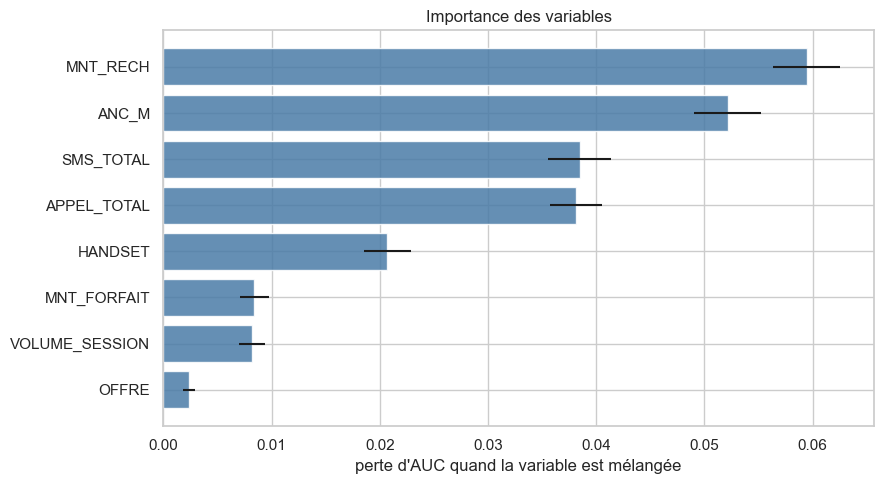

In [11]:

X_tr, X_te, y_tr, y_te = train_test_split(
    X_co, y, test_size=0.20, random_state=42, stratify=y)

modele_comportemental = HistGradientBoostingClassifier(
    max_iter=250, learning_rate=0.06, random_state=42)
modele_comportemental.fit(X_tr, y_tr)

importance = permutation_importance(
    modele_comportemental, X_te, y_te,
    n_repeats=10, random_state=42, scoring='roc_auc', n_jobs=-1)

ordre = np.argsort(importance.importances_mean)

plt.figure(figsize=(9, 5))
plt.barh(np.array(X_co.columns)[ordre], importance.importances_mean[ordre],
         xerr=importance.importances_std[ordre], color='#4a7ba7', alpha=0.85)
plt.xlabel("perte d'AUC quand la variable est mélangée")
plt.title('Importance des variables')
plt.tight_layout()
plt.show()



### Lecture

| Variable | Perte d'AUC |
|---|---|
| `MNT_RECH` | +0,068 |
| `ANC_M` | +0,046 |
| `SMS_TOTAL` | +0,040 |
| `APPEL_TOTAL` | +0,035 |
| `HANDSET` | +0,017 |
| `VOLUME_SESSION` | +0,008 |
| `MNT_FORFAIT` | +0,008 |
| `OFFRE` | +0,002 |

`OFFRE` n'apporte presque rien malgré ses 65 modalités. Les variables utiles
sont les recharges, l'ancienneté et les volumes d'appels et SMS.



## 7. Comparaison finale


In [12]:

comparaison = pd.DataFrame([
    {'critère': 'Colonnes', 'opérationnel': '9 (avec STATUT)',
     'comportemental': '8 (sans STATUT)'},
    {'critère': 'AUC global',
     'opérationnel': f'{tableau.loc["GradientBoosting / opérationnel", "AUC"]:.3f}',
     'comportemental': f'{tableau.loc["GradientBoosting / comportemental", "AUC"]:.3f}'},
    {'critère': 'AUC sur clients actifs',
     'opérationnel': f'{roc_auc_score(y.to_numpy()[est_actif], np.asarray(probas["GradientBoosting / opérationnel"])[est_actif]):.3f}',
     'comportemental': f'{roc_auc_score(y.to_numpy()[est_actif], np.asarray(probas["GradientBoosting / comportemental"])[est_actif]):.3f}'},
    {'critère': "Ce qu'il apprend", 'opérationnel': 'un état constaté',
     'comportemental': 'un comportement'},
    {'critère': 'Action possible', 'opérationnel': 'aucune',
     'comportemental': 'oui'},
    {'critère': 'Usage', 'opérationnel': 'reporting',
     'comportemental': 'ciblage des relances'},
])
print(comparaison.to_string(index=False))


               critère     opérationnel       comportemental
              Colonnes  9 (avec STATUT)      8 (sans STATUT)
            AUC global            0.921                0.809
AUC sur clients actifs            0.794                0.789
      Ce qu'il apprend un état constaté      un comportement
       Action possible           aucune                  oui
                 Usage        reporting ciblage des relances



## 8. Conclusion

| | Opérationnel | Comportemental |
|---|---|---|
| AUC global | 0,921 | 0,809 |
| AUC sur clients actifs | 0,793 | 0,789 |
| Utilité pour agir | faible | forte |

Le modèle opérationnel gagne 0,11 d'AUC, mais cet avantage vient des clients
déjà suspendus. Sur la population où une action reste possible, les deux
versions se valent.

**Pour cibler des relances** : le modèle comportemental, entraîné sur les
clients actifs. **Pour du reporting** : le modèle opérationnel.

### Limites

1. Pas de validation temporelle : une seule observation par client, un seul
   label. Les scores sont optimistes.
2. Déséquilibre de 28 / 72 : l'AUC est adaptée, la précision reste modérée.
3. Les variables catégorielles sont encodées en codes, ce qui convient aux
   arbres mais pas à un modèle linéaire.
4. `OFFRE` compte 65 modalités, avec un risque de mémorisation sur les offres
   rares.

Pour valider le modèle, il faudrait plusieurs mois de labels : entraîner sur
les premiers mois, tester sur les suivants.
